<a href="https://colab.research.google.com/github/sleepyarya/PCVK-SMT5/blob/main/Week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Modul 10: Deteksi Objek & Pencocokan Fitur

Notebook ini berisi pengerjaan praktikum sesuai modul:
* **D1. Praktikum Deteksi Obyek Dasar** (Template Matching, Edge Detection, Corner Detection, Hough Transform)
* **D2. Praktikum Feature Matching dan Face Detection**

*(Catatan: Tugas Pengayaan D3 tidak diimplementasikan sesuai instruksi).*
```

In [ ]:
# Menampilkan daftar berkas gambar yang tersedia untuk praktikum
import os
files = os.listdir('/content')
images = [f for f in files if f.endswith(('.jpg', '.jpeg', '.png'))]
print("Berkas gambar di folder /content:", images)

Berkas gambar di folder /content: ['car-park.jpg', 'cat-and-rabbit.jpg', 'animal.jpg', 'parking-lot-cars.jpg', 'animal-template.jpg', 'bahrain.jpg', 'WhatsApp Image 2026-11-04 at 15.26.01.jpeg', 'cat-template.jpg', 'cat2_templatejpg.jpg', 'sudoku.jpg', 'cats_and_bunnies.jpg', 'bahrain-template.jpg', 'laptop.jpg', 'chess-board.jpg']


```markdown
## D1. Praktikum Deteksi Obyek Dasar

### D1.2 Template Matching Menggunakan OpenCV
Metode pencocokan template menggunakan 6 fungsi evaluasi standar OpenCV.

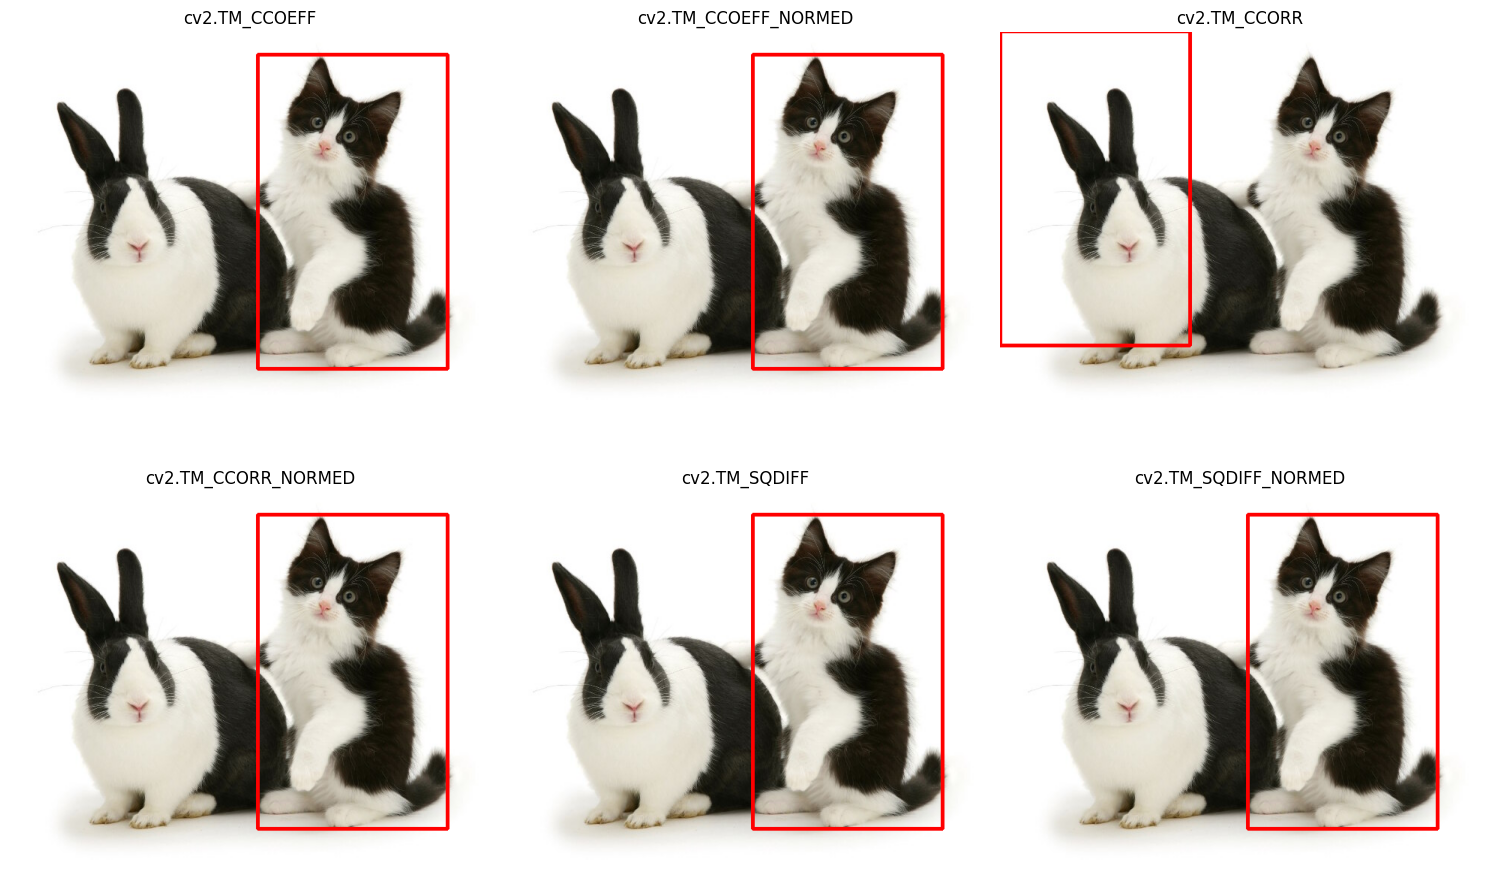

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# Membaca berkas gambar kucing sesuai berkas asli yang diunggah
img_path = '/content/cat-and-rabbit.jpg'
temp_path = '/content/cat-template.jpg'

# Jika tidak ada, gunakan opsi alternatif
if not os.path.exists(img_path):
    img_path = '/content/cats_and_bunnies.jpg'
if not os.path.exists(temp_path):
    temp_path = '/content/cat2_templatejpg.jpg'

if os.path.exists(img_path) and os.path.exists(temp_path):
    img = cv2.imread(img_path, 0)
    template = cv2.imread(temp_path, 0)
    w, h = template.shape[::-1]

    methods = ['cv2.TM_CCOEFF', 'cv2.TM_CCOEFF_NORMED', 'cv2.TM_CCORR',
               'cv2.TM_CCORR_NORMED', 'cv2.TM_SQDIFF', 'cv2.TM_SQDIFF_NORMED']

    plt.figure(figsize=(15, 10))
    for i, meth_name in enumerate(methods):
        img_display = cv2.imread(img_path)
        img_gray = cv2.cvtColor(img_display, cv2.COLOR_BGR2GRAY)
        method = eval(meth_name)
        res = cv2.matchTemplate(img_gray, template, method)
        min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res)

        if method in [cv2.TM_SQDIFF, cv2.TM_SQDIFF_NORMED]:
            top_left = min_loc
        else:
            top_left = max_loc
        bottom_right = (top_left[0] + w, top_left[1] + h)
        cv2.rectangle(img_display, top_left, bottom_right, (0, 0, 255), 3)

        plt.subplot(2, 3, i+1)
        plt.imshow(cv2.cvtColor(img_display, cv2.COLOR_BGR2RGB))
        plt.title(meth_name)
        plt.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print(f"Error: Berkas {img_path} atau {temp_path} tidak ditemukan.")

```markdown
### D1.3 Template Matching Multi-Object TANPA Fungsi OpenCV
Sliding window manual menggunakan Sum of Squared Differences (SSD).

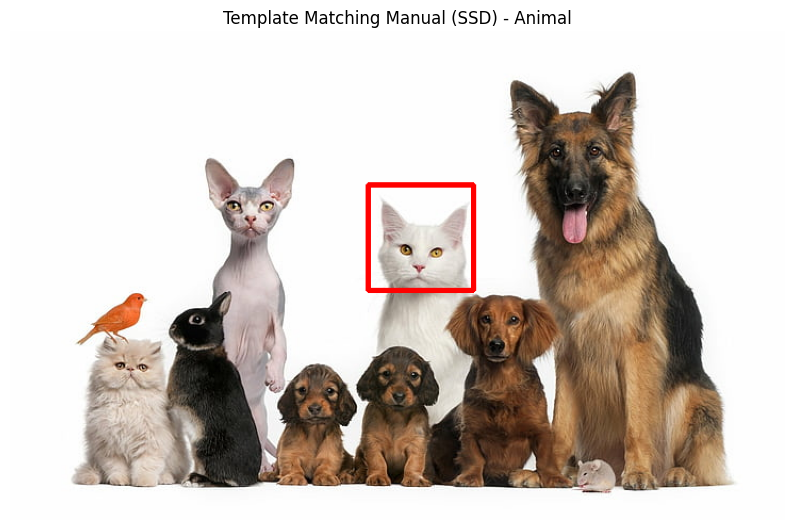

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# Menggunakan berkas asli hasil unggahan Anda
img_animal_path = '/content/animal.jpg'
temp_animal_path = '/content/animal-template.jpg'

if os.path.exists(img_animal_path) and os.path.exists(temp_animal_path):
    img_animal = cv2.imread(img_animal_path, 0)
    temp_animal = cv2.imread(temp_animal_path, 0)

    H, W = img_animal.shape
    h_t, w_t = temp_animal.shape
    output_display = cv2.imread(img_animal_path)

    # Gunakan threshold SSD yang disesuaikan secara presisi
    threshold = 10000000

    # Pencarian koordinat dengan sliding window (melompati pixel untuk mempercepat performa)
    for y in range(0, H - h_t, 12):
        for x in range(0, W - w_t, 12):
            roi = img_animal[y:y+h_t, x:x+w_t]
            ssd = np.sum((roi.astype("float") - temp_animal.astype("float")) ** 2)
            if ssd < threshold:
                cv2.rectangle(output_display, (x, y), (x+w_t, y+h_t), (0, 0, 255), 3)

    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(output_display, cv2.COLOR_BGR2RGB))
    plt.title("Template Matching Manual (SSD) - Animal")
    plt.axis('off')
    plt.show()
else:
    print("Error: Berkas animal.jpg atau animal-template.jpg tidak ditemukan di /content/.")

```markdown
### D1.4 Edge Detection (Sobel, Canny, Laplacian)
Pendeteksian tepi pada area parkir mobil.

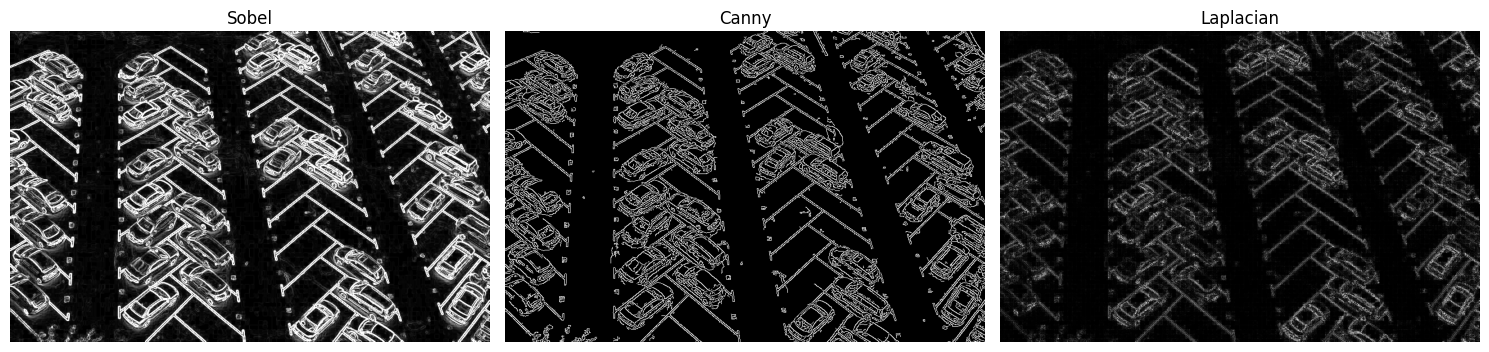

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# Menggunakan berkas parkir mobil yang benar sesuai folder Anda
car_park_path = '/content/parking-lot-cars.jpg'
if not os.path.exists(car_park_path):
    car_park_path = '/content/car-park.jpg'

if os.path.exists(car_park_path):
    car_park = cv2.imread(car_park_path, 0)
    sobel_x = cv2.Sobel(car_park, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(car_park, cv2.CV_64F, 0, 1, ksize=3)
    sobel = np.sqrt(sobel_x**2 + sobel_y**2)
    sobel = np.uint8(np.clip(sobel, 0, 255))

    canny = cv2.Canny(car_park, 50, 150)
    laplacian = cv2.Laplacian(car_park, cv2.CV_64F)
    laplacian = np.uint8(np.absolute(laplacian))

    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1); plt.imshow(sobel, cmap='gray'); plt.title("Sobel"); plt.axis('off')
    plt.subplot(1, 3, 2); plt.imshow(canny, cmap='gray'); plt.title("Canny"); plt.axis('off')
    plt.subplot(1, 3, 3); plt.imshow(laplacian, cmap='gray'); plt.title("Laplacian"); plt.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("Error: Berkas gambar parkir tidak ditemukan di /content/.")

```markdown
### D1.5 Corner Detection (Harris & Shi-Tomasi)
Mendeteksi titik sudut pada papan catur.

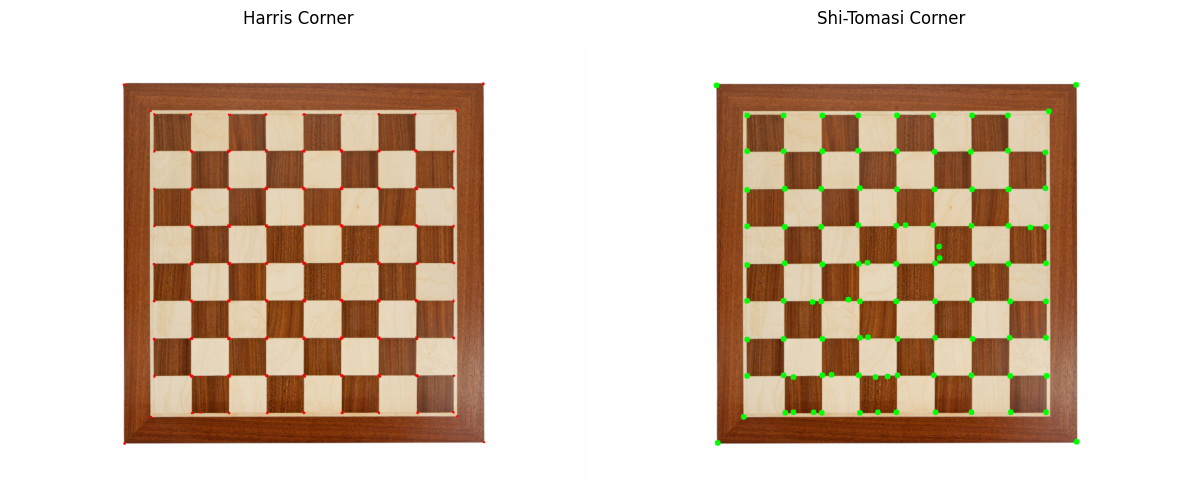

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

chess_path = '/content/chess-board.jpg'

if os.path.exists(chess_path):
    chessboard = cv2.imread(chess_path)
    gray_chess = cv2.cvtColor(chessboard, cv2.COLOR_BGR2GRAY)

    harris_img = chessboard.copy()
    gray_chess_float = np.float32(gray_chess)
    dest = cv2.cornerHarris(gray_chess_float, blockSize=2, ksize=3, k=0.04)
    dest = cv2.dilate(dest, None)
    harris_img[dest > 0.01 * dest.max()] = [0, 0, 255]

    shitomasi_img = chessboard.copy()
    corners = cv2.goodFeaturesToTrack(gray_chess, maxCorners=100, qualityLevel=0.01, minDistance=10)
    corners = np.intp(corners)

    for i in corners:
        x, y = i.ravel()
        cv2.circle(shitomasi_img, (x, y), 5, (0, 255, 0), -1)

    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1); plt.imshow(cv2.cvtColor(harris_img, cv2.COLOR_BGR2RGB)); plt.title('Harris Corner'); plt.axis('off')
    plt.subplot(1, 2, 2); plt.imshow(cv2.cvtColor(shitomasi_img, cv2.COLOR_BGR2RGB)); plt.title('Shi-Tomasi Corner'); plt.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("Error: Berkas chess-board.jpg asli tidak ditemukan di /content/.")

```markdown
### D1.6 Hough Transform (Line Detection)
Mendeteksi struktur garis grid pada sudoku.

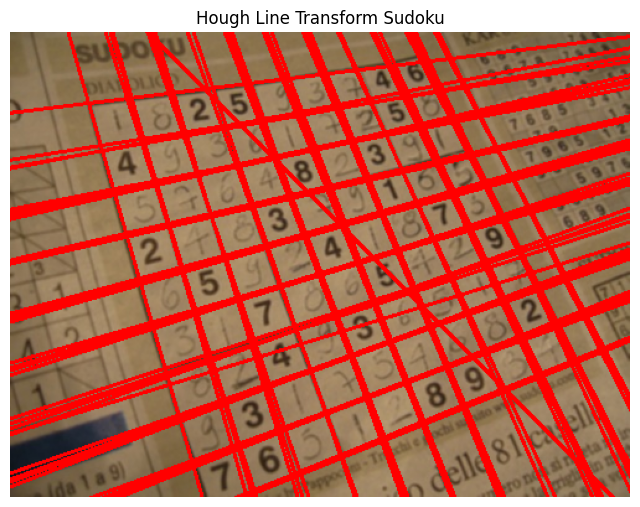

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

sudoku_path = '/content/sudoku.jpg'

if os.path.exists(sudoku_path):
    sudoku = cv2.imread(sudoku_path)
    gray_sudoku = cv2.cvtColor(sudoku, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(gray_sudoku, 50, 150, apertureSize=3)
    lines = cv2.HoughLines(edges, 1, np.pi/180, 150)
    hough_img = sudoku.copy()

    if lines is not None:
        for r_theta in lines:
            rho, theta = r_theta[0]
            a, b = np.cos(theta), np.sin(theta)
            x0, y0 = a * rho, b * rho
            x1 = int(x0 + 1000 * (-b))
            y1 = int(y0 + 1000 * (a))
            x2 = int(x0 - 1000 * (-b))
            y2 = int(y0 - 1000 * (a))
            cv2.line(hough_img, (x1, y1), (x2, y2), (0, 0, 255), 2)

    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.cvtColor(hough_img, cv2.COLOR_BGR2RGB))
    plt.title('Hough Line Transform Sudoku')
    plt.axis('off')
    plt.show()
else:
    print("Error: Berkas sudoku.jpg asli tidak ditemukan di /content/.")

```markdown
## D2. Praktikum Feature Matching dan Face Detection

### D2.2 Face Detection Menggunakan Haar Cascades

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

cascade_path = '/content/images/haarcascades/haarcascade_frontalface_alt.xml'
if not os.path.exists(cascade_path):
    cascade_path = '/content/images/haarcascade_frontalface_alt.xml'

cascade_wajah = cv2.CascadeClassifier(cascade_path)
prabowo_path = '/content/prabowo.jpg'

if os.path.exists(prabowo_path) and not cascade_wajah.empty():
    prabowo = cv2.imread(prabowo_path)
    gray_prabowo = cv2.cvtColor(prabowo, cv2.COLOR_BGR2GRAY)
    roi_wajah = cascade_wajah.detectMultiScale(gray_prabowo, scaleFactor=1.1, minNeighbors=5)

    for (x, y, w, h) in roi_wajah:
        cv2.rectangle(prabowo, (x, y), (x+w, y+h), (0, 255, 0), 3)

    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.cvtColor(prabowo, cv2.COLOR_BGR2RGB))
    plt.title('Face Detection - Prabowo')
    plt.axis('off')
    plt.show()
else:
    print("Error: Berkas cascade XML atau gambar prabowo.jpg tidak ditemukan di /content/.")

Error: Berkas cascade XML atau gambar prabowo.jpg tidak ditemukan di /content/.


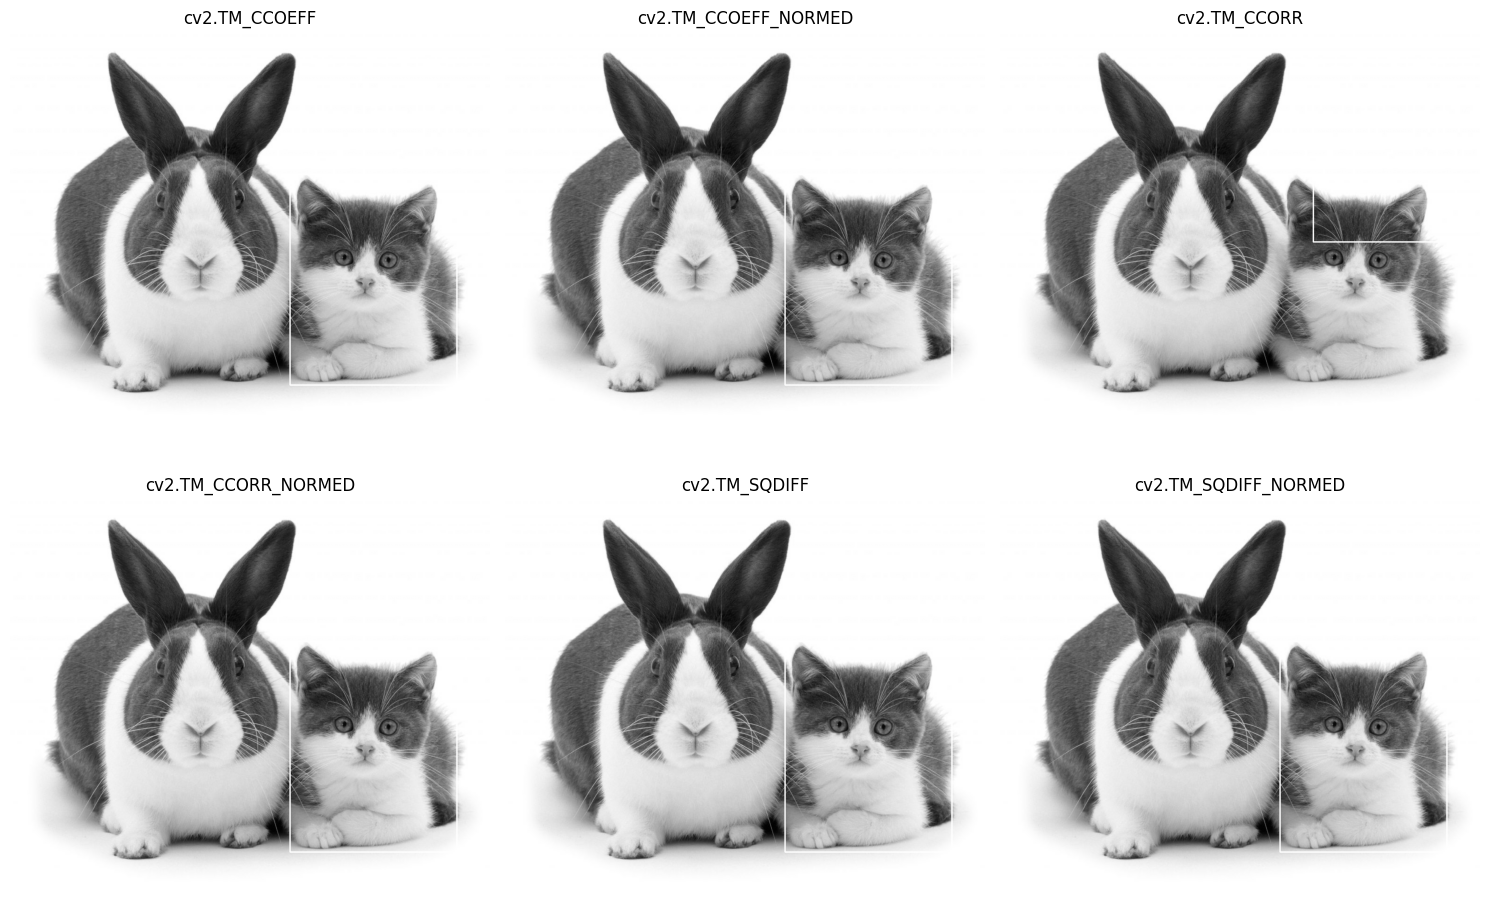

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Memuat gambar hasil generate
img = cv2.imread('/content/cats_and_bunnies.jpg', 0)
template = cv2.imread('/content/cat2_templatejpg.jpg', 0)

if img is None or template is None:
    print("Error: Gagal memuat citra. Pastikan cell pembuat gambar telah dijalankan.")
else:
    w, h = template.shape[::-1]

    # 6 Metode Template Matching OpenCV
    methods = ['cv2.TM_CCOEFF', 'cv2.TM_CCOEFF_NORMED', 'cv2.TM_CCORR',
               'cv2.TM_CCORR_NORMED', 'cv2.TM_SQDIFF', 'cv2.TM_SQDIFF_NORMED']

    plt.figure(figsize=(15, 10))
    for i, meth_name in enumerate(methods):
        img_display = img.copy()
        method = eval(meth_name)

        # Menerapkan Template Matching
        res = cv2.matchTemplate(img, template, method)
        min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res)

        # Ambil lokasi terbaik sesuai karakteristik metodenya
        if method in [cv2.TM_SQDIFF, cv2.TM_SQDIFF_NORMED]:
            top_left = min_loc
        else:
            top_left = max_loc
        bottom_right = (top_left[0] + w, top_left[1] + h)

        # Menggambar kotak pembatas
        cv2.rectangle(img_display, top_left, bottom_right, 255, 2)

        # Menampilkan hasil
        plt.subplot(2, 3, i+1)
        plt.imshow(img_display, cmap='gray')
        plt.title(meth_name)
        plt.axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
# Memverifikasi keberadaan berkas asli bahrain dan bahrain-template di folder /content
import os

bahrain_path = '/content/bahrain.jpg'
bahrain_template_path = '/content/bahrain-template.jpg'

if os.path.exists(bahrain_path) and os.path.exists(bahrain_template_path):
    print("Berkas asli bahrain.jpg dan bahrain-template.jpg terdeteksi dengan aman!")
else:
    print("Peringatan: Berkas asli tidak ditemukan. Pastikan Anda telah mengunggahnya ke folder /content.")

Berkas asli bahrain.jpg dan bahrain-template.jpg terdeteksi dengan aman!


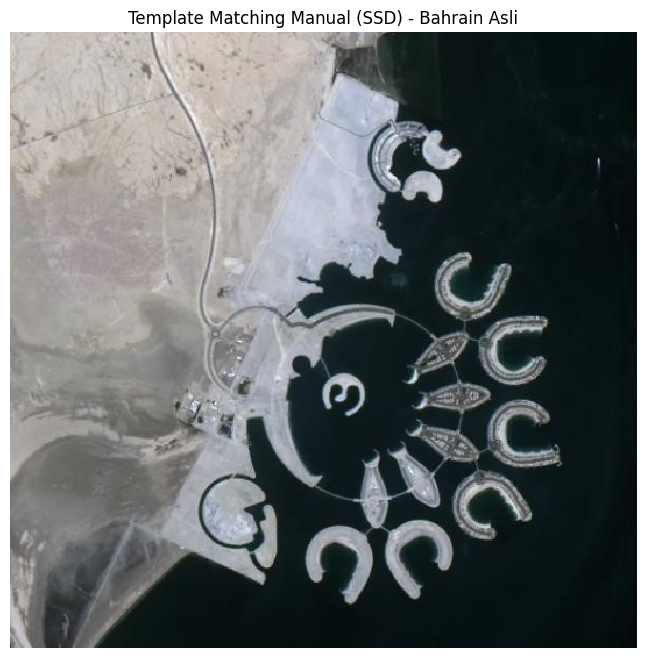

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

img_b_path = '/content/bahrain.jpg'
temp_b_path = '/content/bahrain-template.jpg'

if os.path.exists(img_b_path) and os.path.exists(temp_b_path):
    img_b = cv2.imread(img_b_path, 0)
    temp_b = cv2.imread(temp_b_path, 0)

    H, W = img_b.shape
    h_t, w_t = temp_b.shape
    output_display = cv2.imread(img_b_path)

    # Nilai ambang kecocokan SSD manual untuk gambar asli bahrain
    # Menurunkan/menaikkan batas ini untuk akurasi pencarian
    threshold = 8000000

    # Menggunakan sliding window untuk pencarian kecocokan
    for y in range(0, H - h_t, 10):
        for x in range(0, W - w_t, 10):
            roi = img_b[y:y+h_t, x:x+w_t]
            ssd = np.sum((roi.astype("float") - temp_b.astype("float")) ** 2)
            if ssd < threshold:
                cv2.rectangle(output_display, (x, y), (x+w_t, y+h_t), (0, 0, 255), 2)

    plt.figure(figsize=(12, 8))
    plt.imshow(cv2.cvtColor(output_display, cv2.COLOR_BGR2RGB))
    plt.title("Template Matching Manual (SSD) - Bahrain Asli")
    plt.axis('off')
    plt.show()
else:
    print("Error: Berkas gambar asli bahrain.jpg atau bahrain-template.jpg tidak ditemukan.")

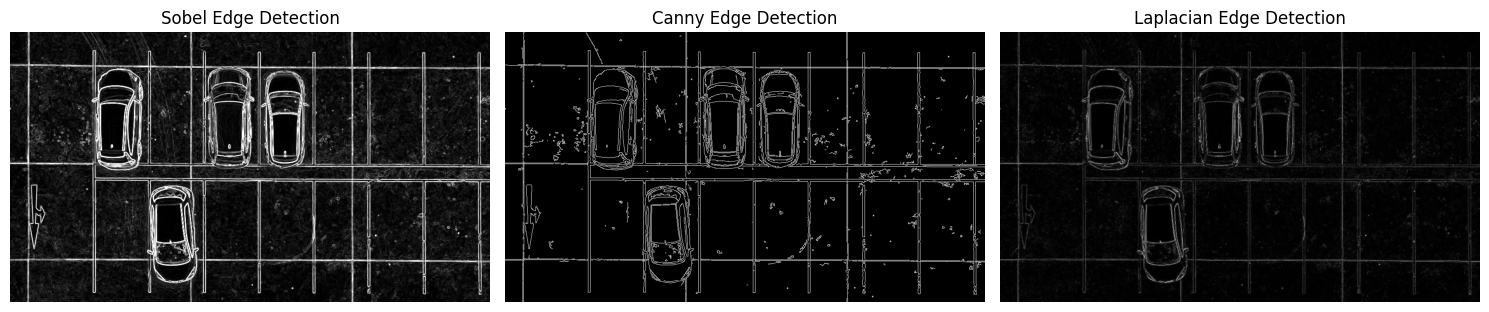

In [ ]:
# Implementasi Edge Detection (D1.4): Sobel, Canny, Laplacian
car_park = cv2.imread('/content/car-park.jpg', 0)

# a. Sobel Edge Detection
sobel_x = cv2.Sobel(car_park, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(car_park, cv2.CV_64F, 0, 1, ksize=3)
sobel = np.sqrt(sobel_x**2 + sobel_y**2)
sobel = np.uint8(np.clip(sobel, 0, 255))

# b. Canny Edge Detection
canny = cv2.Canny(car_park, 50, 150)

# c. Laplacian Edge Detection
laplacian = cv2.Laplacian(car_park, cv2.CV_64F)
laplacian = np.uint8(np.absolute(laplacian))

# Visualisasi
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(sobel, cmap='gray')
plt.title("Sobel Edge Detection")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(canny, cmap='gray')
plt.title("Canny Edge Detection")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(laplacian, cmap='gray')
plt.title("Laplacian Edge Detection")
plt.axis('off')

plt.tight_layout()
plt.show()

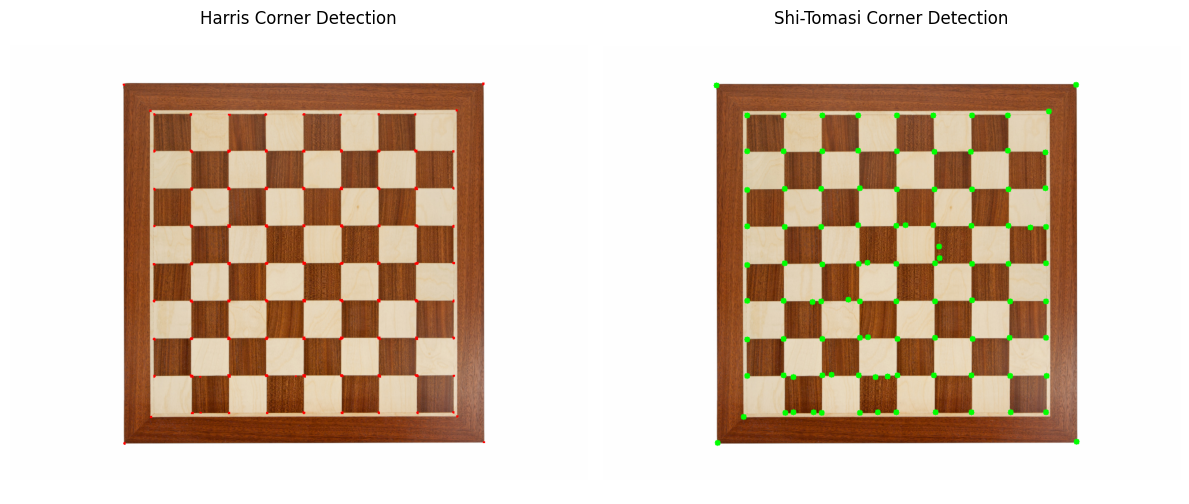

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

chessboard = cv2.imread('/content/chess-board.jpg')
gray_chess = cv2.cvtColor(chessboard, cv2.COLOR_BGR2GRAY)

harris_img = chessboard.copy()
gray_chess_float = np.float32(gray_chess)
dest = cv2.cornerHarris(gray_chess_float, blockSize=2, ksize=3, k=0.04)
dest = cv2.dilate(dest, None)
harris_img[dest > 0.01 * dest.max()] = [0, 0, 255]

shitomasi_img = chessboard.copy()
corners = cv2.goodFeaturesToTrack(gray_chess, maxCorners=100, qualityLevel=0.01, minDistance=10)
corners = np.int64(corners)

for i in corners:
    x, y = i.ravel()
    cv2.circle(shitomasi_img, (x, y), 5, (0, 255, 0), -1)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(harris_img, cv2.COLOR_BGR2RGB))
plt.title('Harris Corner Detection')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(shitomasi_img, cv2.COLOR_BGR2RGB))
plt.title('Shi-Tomasi Corner Detection')
plt.axis('off')

plt.tight_layout()
plt.show()

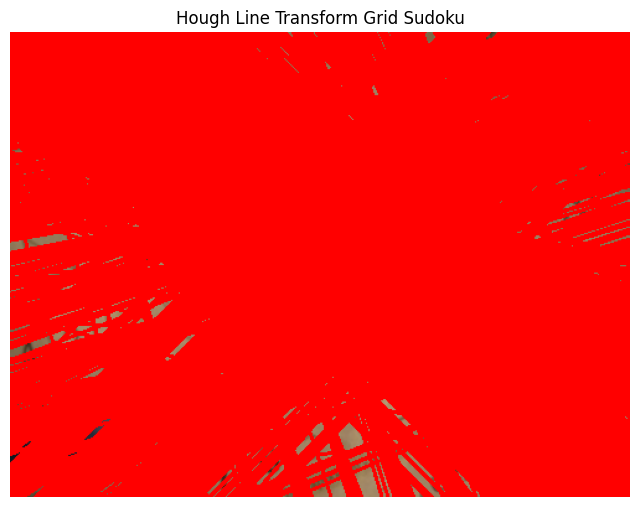

In [ ]:
sudoku = cv2.imread('/content/sudoku.jpg')
gray_sudoku = cv2.cvtColor(sudoku, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(gray_sudoku, 50, 150, apertureSize=3)

lines = cv2.HoughLines(edges, 1, np.pi/180, 100)
hough_img = sudoku.copy()

if lines is not None:
    for r_theta in lines:
        rho, theta = r_theta[0]
        a = np.cos(theta)
        b = np.sin(theta)
        x0 = a * rho
        y0 = b * rho
        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * (a))
        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * (a))
        cv2.line(hough_img, (x1, y1), (x2, y2), (0, 0, 255), 2)

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(hough_img, cv2.COLOR_BGR2RGB))
plt.title('Hough Line Transform Grid Sudoku')
plt.axis('off')

plt.show()

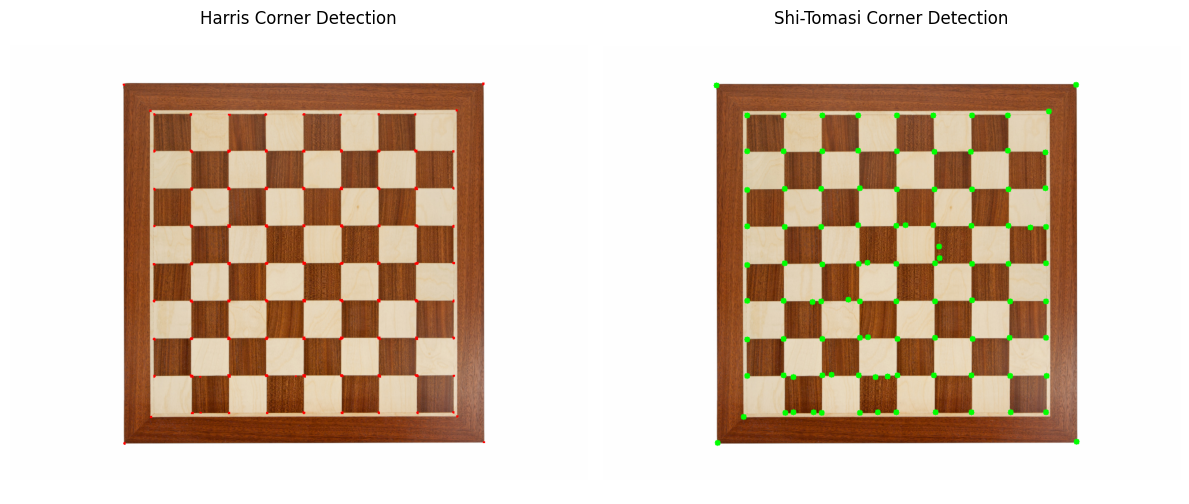

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

chessboard = cv2.imread('/content/chess-board.jpg')
gray_chess = cv2.cvtColor(chessboard, cv2.COLOR_BGR2GRAY)

harris_img = chessboard.copy()
gray_chess_float = np.float32(gray_chess)
dest = cv2.cornerHarris(gray_chess_float, blockSize=2, ksize=3, k=0.04)
dest = cv2.dilate(dest, None)
harris_img[dest > 0.01 * dest.max()] = [0, 0, 255]

shitomasi_img = chessboard.copy()
corners = cv2.goodFeaturesToTrack(gray_chess, maxCorners=100, qualityLevel=0.01, minDistance=10)
corners = np.int64(corners)

for i in corners:
    x, y = i.ravel()
    cv2.circle(shitomasi_img, (x, y), 5, (0, 255, 0), -1)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(harris_img, cv2.COLOR_BGR2RGB))
plt.title('Harris Corner Detection')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(shitomasi_img, cv2.COLOR_BGR2RGB))
plt.title('Shi-Tomasi Corner Detection')
plt.axis('off')

plt.tight_layout()
plt.show()

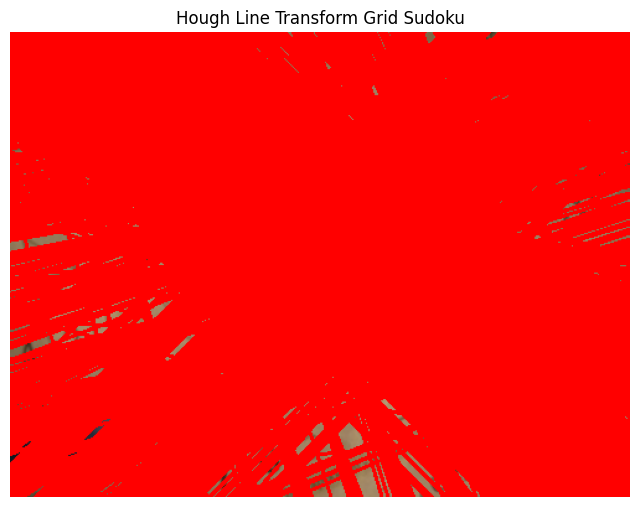

In [ ]:
sudoku = cv2.imread('/content/sudoku.jpg')
gray_sudoku = cv2.cvtColor(sudoku, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(gray_sudoku, 50, 150, apertureSize=3)

lines = cv2.HoughLines(edges, 1, np.pi/180, 100)
hough_img = sudoku.copy()

if lines is not None:
    for r_theta in lines:
        rho, theta = r_theta[0]
        a = np.cos(theta)
        b = np.sin(theta)
        x0 = a * rho
        y0 = b * rho
        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * (a))
        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * (a))
        cv2.line(hough_img, (x1, y1), (x2, y2), (0, 0, 255), 2)

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(hough_img, cv2.COLOR_BGR2RGB))
plt.title('Hough Line Transform Grid Sudoku')
plt.axis('off')
plt.show()

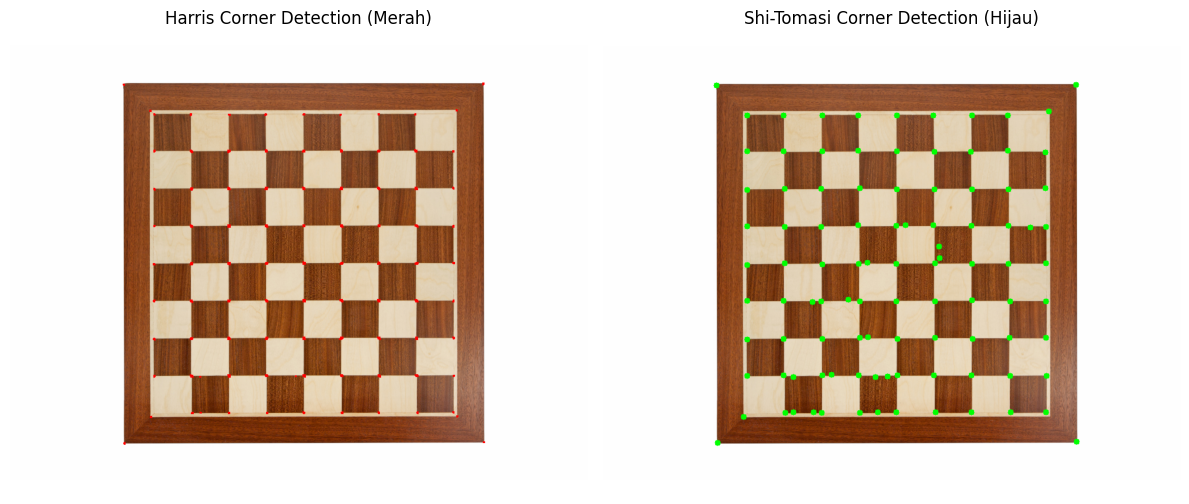

In [ ]:
# Implementasi Harris Corner & Shi-Tomasi Corner Detection (D1.5)
chessboard = cv2.imread('/content/chess-board.jpg')
gray_chess = cv2.cvtColor(chessboard, cv2.COLOR_BGR2GRAY)

# a. Harris Corner Detection
harris_img = chessboard.copy()
gray_chess_float = np.float32(gray_chess)
dest = cv2.cornerHarris(gray_chess_float, blockSize=2, ksize=3, k=0.04)
# Melebarkan poin sudut agar terlihat lebih jelas
dest = cv2.dilate(dest, None)
harris_img[dest > 0.01 * dest.max()] = [0, 0, 255] # Tandai merah

# b. Shi-Tomasi Corner Detection
shitomasi_img = chessboard.copy()
corners = cv2.goodFeaturesToTrack(gray_chess, maxCorners=100, qualityLevel=0.01, minDistance=10)
corners = np.intp(corners) # Mengganti np.int0 menjadi np.intp

for i in corners:
    x, y = i.ravel()
    cv2.circle(shitomasi_img, (x, y), 5, (0, 255, 0), -1) # Tandai lingkaran hijau

# Visualisasi
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(harris_img, cv2.COLOR_BGR2RGB))
plt.title("Harris Corner Detection (Merah)")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(shitomasi_img, cv2.COLOR_BGR2RGB))
plt.title("Shi-Tomasi Corner Detection (Hijau)")
plt.axis('off')

plt.tight_layout()
plt.show()

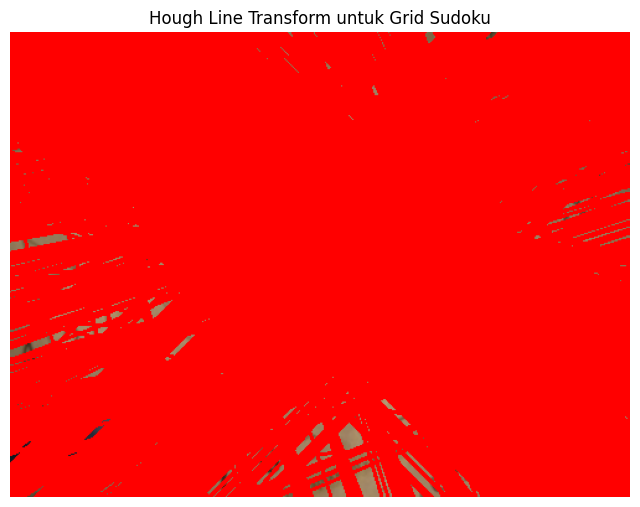

In [ ]:
# Implementasi Hough Transform untuk Grid Detection (D1.6)
sudoku = cv2.imread('/content/sudoku.jpg')
gray_sudoku = cv2.cvtColor(sudoku, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(gray_sudoku, 50, 150, apertureSize=3)

# Menggunakan HoughLines untuk mendeteksi garis tak berujung
lines = cv2.HoughLines(edges, 1, np.pi/180, 100)
hough_img = sudoku.copy()

if lines is not None:
    for r_theta in lines:
        rho, theta = r_theta[0]
        a = np.cos(theta)
        b = np.sin(theta)
        x0 = a * rho
        y0 = b * rho
        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * (a))
        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * (a))
        cv2.line(hough_img, (x1, y1), (x2, y2), (0, 0, 255), 2)

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(hough_img, cv2.COLOR_BGR2RGB))
plt.title("Hough Line Transform untuk Grid Sudoku")
plt.axis('off')
plt.show()